# Every HIP-4 market in pandas

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/usehyperodds/hyperodds-python/blob/main/notebooks/hip4-in-colab.ipynb)

Run all cells to pull every live HIP-4 outcome market on Hyperliquid into a pandas DataFrame, set HIP-4 prices beside Polymarket on the questions both list, and chart a week of one market on all three venues. It takes about 30 seconds. The [`hyperodds`](https://github.com/usehyperodds/hyperodds-python) package reads the public Hyperodds API, so there is no key to set up.

The outputs saved with it come from a real run. Run it again for live numbers.

In [1]:
%pip install -q "hyperodds[pandas] @ git+https://github.com/usehyperodds/hyperodds-python" matplotlib

Note: you may need to restart the kernel to use updated packages.


The line above installs `hyperodds` from its GitHub repository. Once the package is on PyPI, use `%pip install -q "hyperodds[pandas]" matplotlib` instead.

In [2]:
import pandas as pd
from hyperodds import Hyperodds

ho = Hyperodds()
df = ho.markets.list().to_dataframe()

print(f"{len(df)} live HIP-4 markets from {df.deployer_name.nunique()} deployers, read {pd.Timestamp.now(tz='UTC'):%Y-%m-%d %H:%M} UTC")
df[["title", "deployer_name", "bid", "ask", "fair", "volume_24h", "starts", "settles_at", "settles_by"]].head(10)

305 live HIP-4 markets from 5 deployers, read 2026-11-25 20:30 UTC


,title,deployer_name,bid,ask,fair,volume_24h,starts,settles_at,settles_by
outcome,,,,,,,,,
11492,NBA 2026/2027 winner: Oklahoma City Thunder,Outcome,0.12454,0.12455,NaN,2111600.0,NaT,NaT,2027-06-30 23:59:00+00:00
11493,NBA 2026/2027 winner: San Antonio Spurs,Outcome,0.21010,0.21011,NaN,1750592.0,NaT,NaT,2027-06-30 23:59:00+00:00
11495,NBA 2026/2027 winner: Philadelphia 76ers,Outcome,0.10742,0.10743,NaN,1580823.0,NaT,NaT,2027-06-30 23:59:00+00:00
11497,NBA 2026/2027 winner: Boston Celtics,Outcome,0.08127,0.08128,NaN,1445152.0,NaT,NaT,2027-06-30 23:59:00+00:00
1488,NFL 2027 winner: Buffalo Bills,Outcome,0.15425,0.15426,0.157716,1311577.0,NaT,NaT,2027-02-21 12:00:00+00:00
1481,UEFA Champions League 2026/2027 winner: Arsenal,Outcome,0.14974,0.15057,NaN,1281013.0,NaT,NaT,2027-06-12 12:00:00+00:00
1485,UEFA Champions League 2026/2027 winner: Paris ...,Outcome,0.16880,0.16893,NaN,1207085.0,NaT,NaT,2027-06-12 12:00:00+00:00
1491,NFL 2027 winner: Kansas City Chiefs,Outcome,0.09080,0.09081,0.090883,1150909.0,NaT,NaT,2027-02-21 12:00:00+00:00
1475,English Premier League 2026/2027 winner: Liver...,Outcome,0.12951,0.12952,0.129758,1128693.0,NaT,NaT,2027-06-05 12:00:00+00:00


One row per market, indexed by its outcome id. Prices are decimals from 0 to 1 for the market's first side (`side0`, usually Yes). `fair` is the Hyperodds fair line for that side, where one exists, and `volume_24h` counts contracts traded in the last day, each worth $1 at settlement. Times read as the console shows them: `starts` is a game's start or a decision's time, `settles_at` is when a price market settles at a set time, and every other market, touch markets included, has `settles_by`, the latest it settles. All are UTC.

`df.columns` lists the rest: depth, spreads, the best edge after fees and who settles the market.

## Where the volume is

In [3]:
by_category = (
    df.groupby("category")
    .agg(
        markets=("title", "size"),
        volume_24h=("volume_24h", "sum"),
        with_fair_line=("fair", "count"),
    )
    .sort_values("volume_24h", ascending=False)
)
by_category

,markets,volume_24h,with_fair_line
category,,,
sports,157,32297873.0,12
crypto,82,349729.0,75
equities,19,71065.0,16
commodities,13,56827.0,12
indices,20,27777.0,15
macro,4,12890.0,3
ipo,10,7643.0,0


In [4]:
# @title Chart style
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

%config InlineBackend.figure_format = "retina"

GREEN, VIOLET = "#0e8a4f", "#6250d6"
INK, MUTED, GRID = "#29352e", "#68736b", "#e3e3e0"
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 14,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": INK,
    "font.size": 11,
})


def contracts(x, _=None):
    if x >= 1e6:
        return f"{x / 1e6:.1f}M"
    return f"{x / 1e3:.0f}k" if x >= 1e3 else str(int(x))

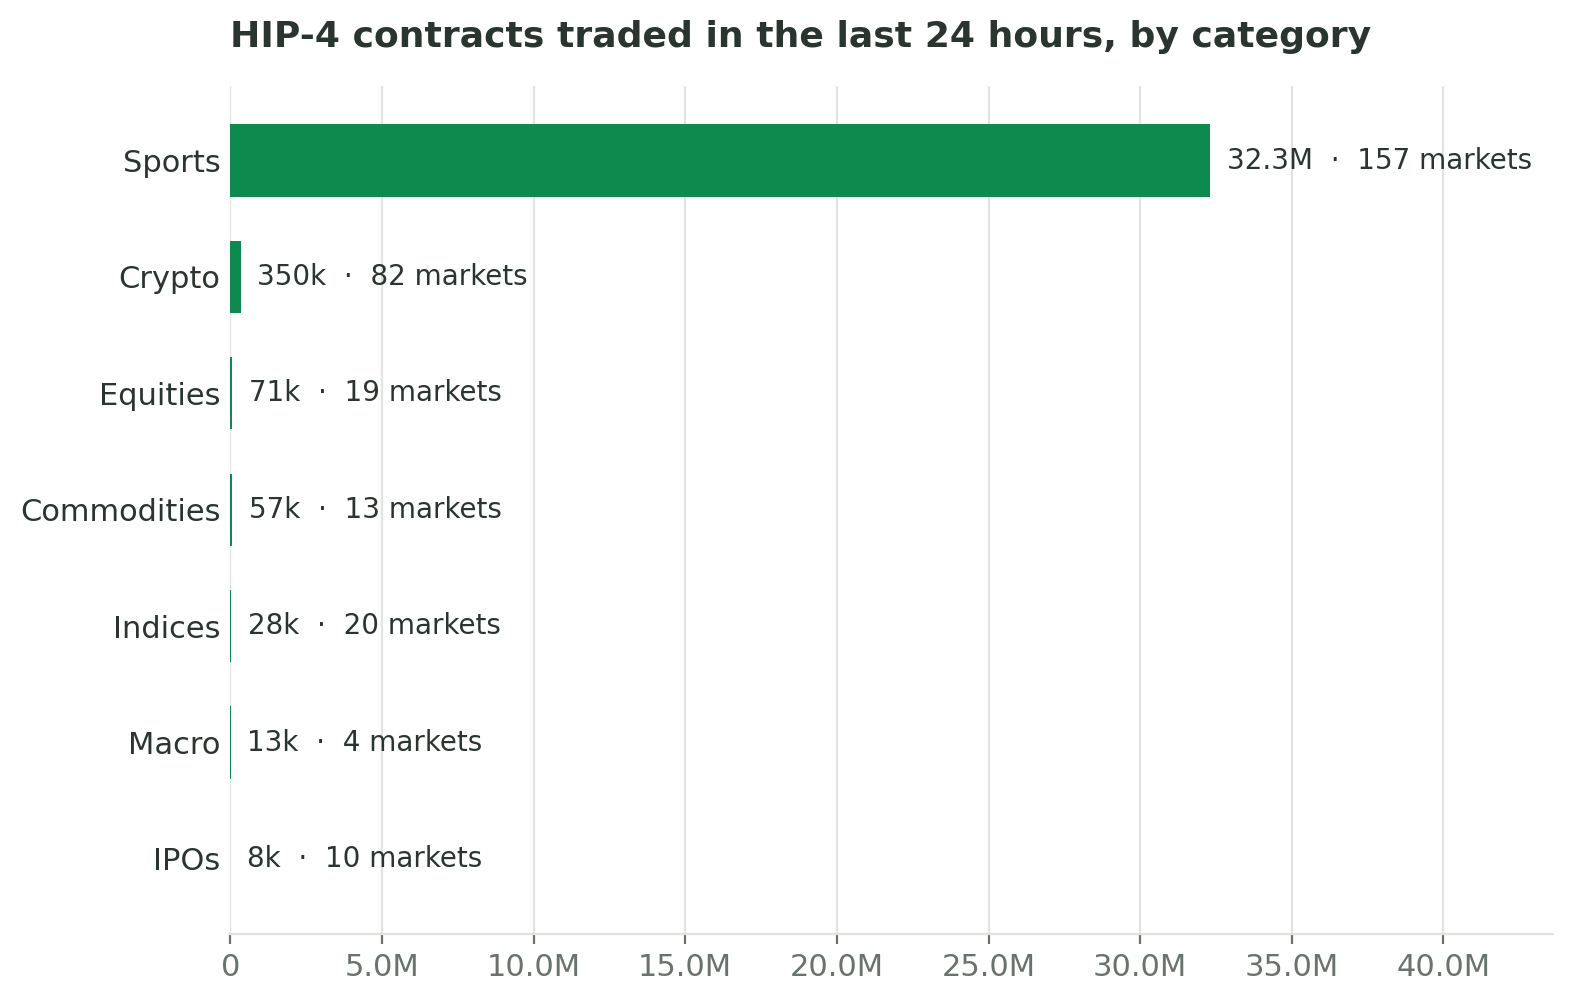

In [5]:
names = {"ipo": "IPOs"}
rows = by_category.sort_values("volume_24h")
fig, ax = plt.subplots(figsize=(8, 0.55 * len(rows) + 1.3))
bars = ax.barh([names.get(c, c.title()) for c in rows.index], rows.volume_24h, color=GREEN, height=0.62)
ax.bar_label(
    bars,
    labels=[f"{contracts(v)}  ·  {n} markets" for v, n in zip(rows.volume_24h, rows.markets)],
    padding=6,
    color=INK,
    fontsize=10,
)
ax.set_xlim(0, rows.volume_24h.max() * 1.35)
ax.xaxis.set_major_formatter(FuncFormatter(contracts))
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("HIP-4 contracts traded in the last 24 hours, by category")
fig.tight_layout()
plt.show()

## HIP-4 next to Polymarket

Hyperodds matches HIP-4 markets to Polymarket and Kalshi markets and grades each match against the rules on both sides: **SAME** settles on the same terms, **CLOSE** differs in a detail such as the price source or a deadline (`differences` names the rule fields), and **DIFFERENT** asks another question, such as another strike.

The next cell reads every matched market in full, ten to a request, and keeps the Polymarket matches graded SAME or CLOSE. Both prices are for the HIP-4 market's first side, already flipped where Polymarket lists the sides the other way round. `gap_pts` is the HIP-4 mid less the Polymarket mid, in percentage points.

A mid only means something when both sides quote near it: a book with a bid at 0.01 and an ask at 0.99 has a mid of 0.50 whatever the market thinks. So the comparison keeps pairs where both books quote within 5 points.

In [6]:
matched = df[df.match_grade.isin(["SAME", "CLOSE"])]
venues = ho.markets.get_many(matched.index).matches_dataframe()
pm = venues[(venues.venue == "pm") & venues.grade.isin(["SAME", "CLOSE"])]
pm = pm[(pm.hl_spread <= 0.05) & (pm.venue_spread <= 0.05)]

print(f"{len(pm)} Polymarket matches with live books on both sides, across {pm.outcome.nunique()} HIP-4 markets")
print(f"Median gap between the two mids: {pm.gap_pts.abs().median():.2f} points")
(
    pm[["title", "venue_title", "grade", "differences", "hl_mid", "venue_mid", "gap_pts"]]
    .sort_values("gap_pts", key=abs, ascending=False)
    .head(10)
)

73 Polymarket matches with live books on both sides, across 73 HIP-4 markets
Median gap between the two mids: 0.35 points


,title,venue_title,grade,differences,hl_mid,venue_mid,gap_pts
111,"BTC touches 55,000 by Dec 1 00:00 UTC","Will Bitcoin dip to $55,000 in November?",CLOSE,"cutoff, source, window",0.244945,0.2150,2.9945
193,"Fed rate decision, December 2026: Hike",Hike of any size: 25 bps increase or 50+ bps i...,SAME,,0.936060,0.9565,-2.0440
242,English Premier League 2026/2027 winner: Chelsea,Will Chelsea win the 2026-27 English Premier L...,SAME,,0.028400,0.0090,1.9400
80,Sporting CP vs Manchester United: Draw,Will Sporting CP vs. Manchester United FC end ...,CLOSE,void,0.291375,0.3050,-1.3625
132,FC Shakhtar Donetsk vs Fenerbahce: Draw,Will FK Shakhtar Donetsk vs. Fenerbahçe SK end...,CLOSE,void,0.312000,0.3250,-1.3000
53,Los Angeles Chargers vs New England Patriots,Patriots vs. Chargers,CLOSE,void,0.482285,0.4950,-1.2715
152,Inter Milan vs VfB Stuttgart: VfB Stuttgart,Will VfB Stuttgart win on 2026-11-25?,CLOSE,void,0.155735,0.1450,1.0735
186,Portland Trail Blazers vs Golden State Warriors,Warriors vs. Trail Blazers,CLOSE,void,0.745195,0.7550,-0.9805
93,Indianapolis Colts vs New York Giants,Giants vs. Colts,CLOSE,void,0.264055,0.2550,0.9055
96,Club Brugge vs Liverpool: Draw,Will Club Brugge KV vs. Liverpool FC end in a ...,CLOSE,void,0.165995,0.1750,-0.9005


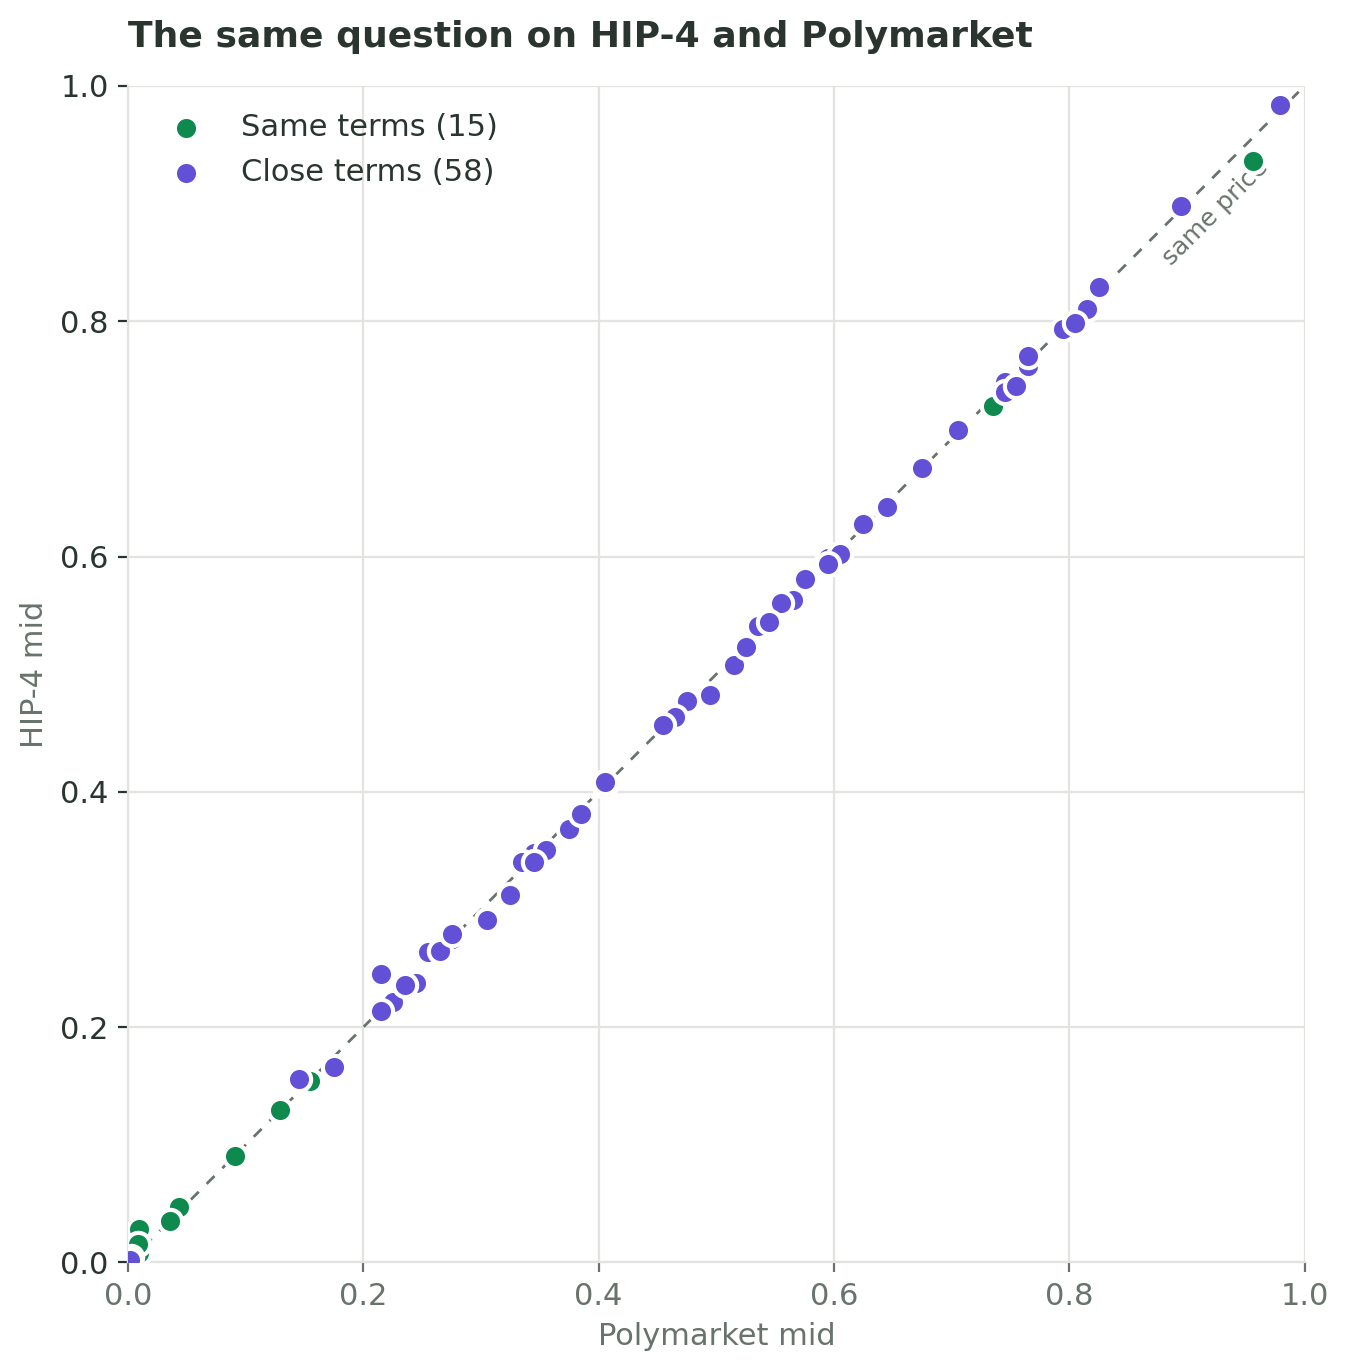

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle=(0, (4, 4)), zorder=1)
ax.text(0.97, 0.93, "same price", color=MUTED, fontsize=9, ha="right", rotation=45, rotation_mode="anchor")
for grade, color in (("SAME", GREEN), ("CLOSE", VIOLET)):
    points = pm[pm.grade == grade]
    ax.scatter(
        points.venue_mid,
        points.hl_mid,
        s=70,
        color=color,
        edgecolor="white",
        linewidth=1.5,
        zorder=3,
        label=f"{grade.title()} terms ({len(points)})",
    )
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xlabel("Polymarket mid")
ax.set_ylabel("HIP-4 mid")
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper left", frameon=False)
ax.set_title("The same question on HIP-4 and Polymarket")
fig.tight_layout()
plt.show()

## Price an order on every venue

Mids leave out fees and depth. `quotes.compare` walks each venue's book for the size you ask and adds that venue's trading fees: `all_in_px` is the price per share after them. Hyperliquid also takes a fee from a winning payout at settlement, so compare on `held_all_in_px`, the price per dollar of payout if the side wins. Polymarket and Kalshi charge only on the trade, so theirs equals `all_in_px`. Here: 100 shares of the first side of the busiest matched market.

In [8]:
busiest = df.loc[pm.outcome.unique()].volume_24h.idxmax()
print(df.loc[busiest, "title"], "·", df.loc[busiest, "url"])
quote = ho.quotes.compare(busiest, side=0, action="buy", shares=100).to_dataframe()
quote[["venue", "title", "grade", "avg_px", "all_in_px", "held_all_in_px", "fees", "filled"]]

NFL 2027 winner: Buffalo Bills · https://usehyperodds.com/m/1488


,venue,title,grade,avg_px,all_in_px,held_all_in_px,fees,filled
0,hl,None,None,0.15426,0.15426,0.154476,0.000,100.0
1,pm,Will the Buffalo Bills win the 2027 NFL league...,SAME,0.16000,0.16672,0.166720,0.672,100.0
2,kx,Will Buffalo win the 2027 Pro Football Champio...,CLOSE,0.16000,0.16950,0.169500,0.950,100.0


## A week of prices

`charts.bars` returns open, high, low, close and volume for any market over its whole history, in bars from one minute to one month. `markets.venue_history` returns the matched venues' prices for the same window, already in the HIP-4 market's terms. Here: hourly closes for the same market, next to Polymarket and Kalshi.

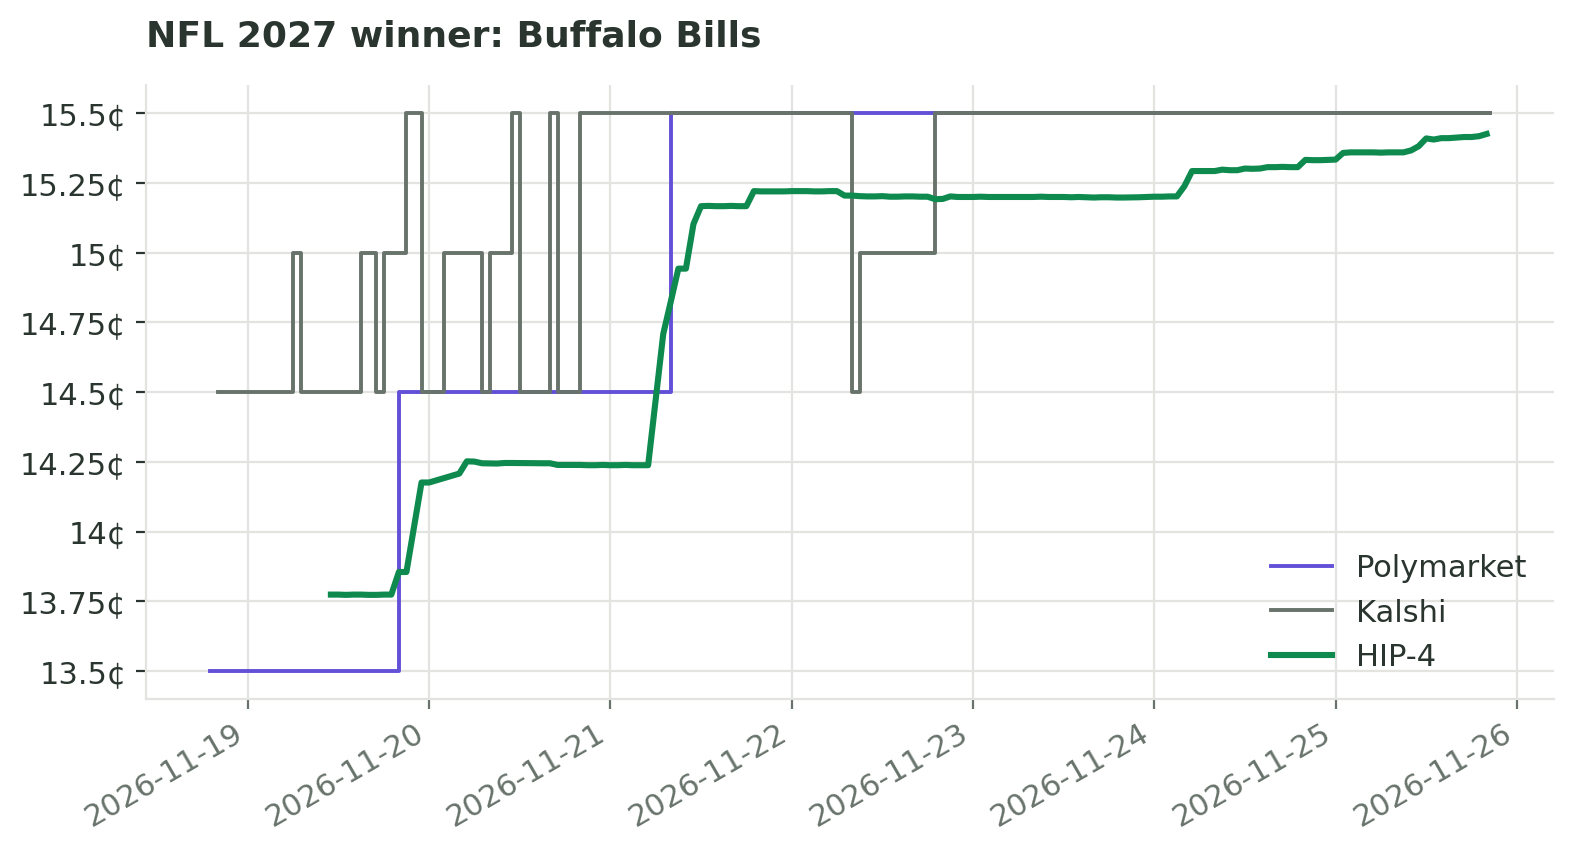

,open,high,low,close,volume
at,,,,,
2026-11-25 16:00:00+00:00,0.15411,0.15422,0.15410,0.15413,127940.0
2026-11-25 17:00:00+00:00,0.15413,0.15431,0.15413,0.15415,146612.0
2026-11-25 18:00:00+00:00,0.15414,0.15415,0.15414,0.15415,107346.0
2026-11-25 19:00:00+00:00,0.15414,0.15420,0.15414,0.15418,76936.0
2026-11-25 20:00:00+00:00,0.15417,0.15432,0.15417,0.15426,31136.0


In [9]:
from datetime import datetime, timedelta, timezone

since = datetime.now(timezone.utc) - timedelta(days=7)
hip4 = ho.charts.bars(busiest, "1h", start=since).to_dataframe()
venue_prices = ho.markets.venue_history(busiest, since, step=60).to_dataframe()

fig, ax = plt.subplots(figsize=(8, 4.4))
for venue, name, color in (("pm", "Polymarket", VIOLET), ("kx", "Kalshi", MUTED)):
    line = venue_prices[venue_prices.venue == venue]
    if len(line):
        ax.step(line["at"], line.p, where="post", color=color, linewidth=1.4, label=name)
ax.plot(hip4.index, hip4.close, color=GREEN, linewidth=2.2, label="HIP-4")
ax.yaxis.set_major_formatter(FuncFormatter(lambda p, _: f"{p * 100:.4g}¢"))
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(loc="best", frameon=False)
ax.set_title(df.loc[busiest, "title"])
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

hip4.tail(5)

## Keep going

- `ho.markets.list(category="crypto", sort="edge")` filters and sorts on the server; `ho.markets.get(outcome)` returns one market with its rules, book, trades and fair-line sources.
- `ho.questions.list().to_dataframe()` sums each multi-outcome question's books.
- `ho.charts.bars(outcome, "1d")` reads a market's daily bars back to its first trade; `"1m"` to `"1M"` set the bar.
- `ho.sheets.markets().to_dataframe()` is the same table a spreadsheet reads, and `ho.forecasts.board()` the public forecast record.
- `for batch in ho.live.listings(): ...` yields new markets as they list.

The [README](https://github.com/usehyperodds/hyperodds-python#readme) covers every call and how the client paces itself under the API's limits. Third-party names identify data sources and platforms; Hyperodds is not affiliated with Hyperliquid, Polymarket, Kalshi, Deribit or Google.